# First Machine Learning Classifier: Predicting Titanic Survival
**Project 04 | Data Science & AI | InternCircle**

**Goal:** Train a Decision Tree classifier with scikit-learn, test it on data it has never seen, compare it with a simple baseline, and explain the results honestly.

**Tools:** Python, pandas, scikit-learn, matplotlib, seaborn

---
## 1. The Prediction
> **Predict whether a passenger survived the Titanic from their ticket class, sex, age and fare.**

- **Target (what I predict):** `survived` (1 = survived, 0 = did not survive)
- **Features (what I use):** `pclass` (ticket class), `sex`, `age`, `fare`

This is a **classification** problem (two possible answers), so the main metrics are accuracy and the confusion matrix. Because the target is 0 or 1, I also report the mean squared error (MSE), and explain what it means here.

## 2. Prepare the Data

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, confusion_matrix, mean_squared_error,
                             classification_report)

sns.set_theme(style="whitegrid")
BLUE, ORANGE = "#0072B2", "#E69F00"

raw = sns.load_dataset("titanic")[["survived", "pclass", "sex", "age", "fare"]]
print("Rows before cleaning:", len(raw))
print("Missing values per column:")
print(raw.isna().sum())

Rows before cleaning: 891
Missing values per column:
survived      0
pclass        0
sex           0
age         177
fare          0
dtype: int64


In [2]:
df = raw.dropna().copy()
df["sex"] = (df["sex"] == "female").astype(int)   # female = 1, male = 0

print("Rows after dropping missing values:", len(df), "| rows removed:", len(raw) - len(df))
print("Overall survival rate:", round(df["survived"].mean(), 3))
df.head()

Rows after dropping missing values: 714 | rows removed: 177
Overall survival rate: 0.406


,survived,pclass,sex,age,fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


**Cleaning choices:**
- Only `age` has missing values (177 rows). I **drop** those rows, as the guide allows, which leaves **714 passengers**. This is simple, but it throws away about 20% of the data (see limitations).
- `sex` is turned into numbers because the model needs numeric input: **female = 1, male = 0**.
- Overall, about 40.6% of the remaining passengers survived.

## 3. Split the Data
I split into **80% training** (the model learns from this) and **20% test** (kept hidden to check the model). `stratify=y` keeps the survival rate the same in both sets, and `random_state=42` makes the result repeatable.

In [3]:
X = df.drop(columns="survived")
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Survival rate in training set:", round(y_train.mean(), 3))
print("Survival rate in test set    :", round(y_test.mean(), 3))

Training rows: 571 | Test rows: 143
Survival rate in training set: 0.406
Survival rate in test set    : 0.406


## 4. Set a Baseline
A baseline is the accuracy of a model with no intelligence: **always guess the most common outcome** (here, "did not survive"). My model must beat this to be useful.

In [4]:
baseline = max(y_test.mean(), 1 - y_test.mean())
print("Baseline accuracy (always guess 'did not survive'):", round(baseline, 3))

Baseline accuracy (always guess 'did not survive'): 0.594


**Baseline = 59.4%.** A model that just says "did not survive" for everyone would be right 59.4% of the time.

## 5. Train the Model
I fit a `DecisionTreeClassifier(max_depth=4, random_state=42)` on the **training data only**.

In [5]:
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)
print("Model trained. Tree depth:", model.get_depth(), "| leaves:", model.get_n_leaves())

Model trained. Tree depth: 4 | leaves: 16


## 6. Evaluate on the Test Set

In [6]:
pred = model.predict(X_test)

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, pred)
mse = mean_squared_error(y_test, pred)

print(f"Baseline accuracy      : {baseline:.3f}")
print(f"Training accuracy      : {train_acc:.3f}")
print(f"Test accuracy          : {test_acc:.3f}")
print(f"Improvement over baseline: +{(test_acc - baseline) * 100:.1f} percentage points")
print(f"MSE on the test set    : {mse:.3f}")

Baseline accuracy      : 0.594
Training accuracy      : 0.848
Test accuracy          : 0.797
Improvement over baseline: +20.3 percentage points
MSE on the test set    : 0.203


[[72 13]
 [16 42]]


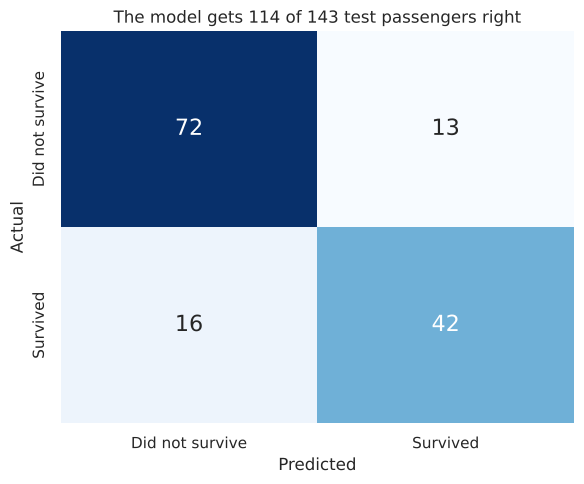

In [7]:
cm = confusion_matrix(y_test, pred)
print(cm)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 16},
            xticklabels=["Did not survive", "Survived"],
            yticklabels=["Did not survive", "Survived"], ax=ax)
ax.set(title="The model gets 114 of 143 test passengers right",
       xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

### Reading the confusion matrix
Rows are the **actual** outcome and columns are the **predicted** outcome (143 test passengers):

| | Predicted: did not survive | Predicted: survived |
|---|---|---|
| **Actual: did not survive** | **72** true negatives | **13** false positives |
| **Actual: survived** | **16** false negatives | **42** true positives |

- **72 (true negatives):** the model said "did not survive" and was right.
- **42 (true positives):** the model said "survived" and was right.
- **13 (false positives):** the model said "survived" but the passenger died.
- **16 (false negatives):** the model said "did not survive" but the passenger actually survived.

**Accuracy = (72 + 42) / 143 = 79.7%**, which beats the 59.4% baseline by about 20 percentage points.

**MSE = 0.203.** With a 0/1 target, the squared error of each prediction is 0 (right) or 1 (wrong), so the MSE is simply the share of wrong predictions (29 / 143 = 0.203), which equals 1 minus the accuracy. MSE is mainly used for regression (predicting numbers like house prices); here it tells the same story as accuracy.

In [8]:
print(classification_report(y_test, pred, target_names=["Did not survive", "Survived"], digits=2))

                 precision    recall  f1-score   support

Did not survive       0.82      0.85      0.83        85
       Survived       0.76      0.72      0.74        58

       accuracy                           0.80       143
      macro avg       0.79      0.79      0.79       143
   weighted avg       0.80      0.80      0.80       143



**Precision and recall for "Survived":**
- **Precision 0.76:** when the model says someone survived, it is right about 76% of the time (42 of 55).
- **Recall 0.72:** of the people who really survived, the model finds about 72% (42 of 58). It misses 16 survivors.

Accuracy alone can hide this. The model is better at spotting people who did **not** survive (recall about 85%) than people who did.

## 7. Depth and Overfitting
A deeper tree can make more splits and fit the training data more closely. I try `max_depth` from 1 to 12 and compare accuracy on the **training** set and the **test** set.

In [9]:
depths = range(1, 13)
train_scores, test_scores = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_scores.append(t.score(X_train, y_train))
    test_scores.append(t.score(X_test, y_test))

depth_table = pd.DataFrame({"max_depth": list(depths),
                            "train_accuracy": np.round(train_scores, 3),
                            "test_accuracy": np.round(test_scores, 3)})
depth_table["gap"] = (depth_table["train_accuracy"] - depth_table["test_accuracy"]).round(3)
depth_table

,max_depth,train_accuracy,test_accuracy,gap
0,1,0.779,0.783,-0.004
1,2,0.795,0.776,0.019
2,3,0.818,0.811,0.007
3,4,0.848,0.797,0.051
4,5,0.865,0.762,0.103
5,6,0.883,0.783,0.100
6,7,0.916,0.783,0.133
7,8,0.925,0.790,0.135
8,9,0.947,0.769,0.178
9,10,0.956,0.762,0.194


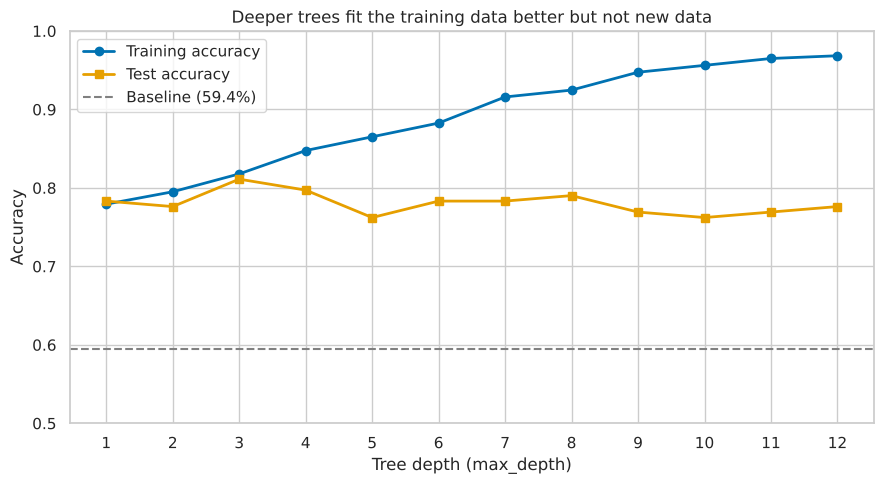

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(list(depths), train_scores, marker="o", color=BLUE, linewidth=2, label="Training accuracy")
ax.plot(list(depths), test_scores, marker="s", color=ORANGE, linewidth=2, label="Test accuracy")
ax.axhline(baseline, color="grey", linestyle="--", label=f"Baseline ({baseline:.1%})")
ax.set(title="Deeper trees fit the training data better but not new data",
       xlabel="Tree depth (max_depth)", ylabel="Accuracy", ylim=(0.5, 1.0))
ax.set_xticks(list(depths))
ax.legend()
plt.tight_layout()
plt.savefig("depth_vs_accuracy.png", dpi=150)
plt.show()

**What the chart shows:**
- **Training accuracy keeps rising** with depth, from 77.9% at depth 1 to **96.8% at depth 12**.
- **Test accuracy does not follow.** It stays around 76% to 81% and ends at 77.6% at depth 12.
- So the gap between training and test accuracy grows from about 0 points at depth 1 to **about 19 points at depth 12**.

**Why very deep trees do worse on new data (overfitting):** a very deep tree has so many splits that it starts to memorise the training passengers, including their random quirks and noise, instead of learning the general pattern (such as "women in higher classes survived more"). Memorised quirks do not repeat in new passengers, so test accuracy stops improving or drops.

**A note on noise:** the best test accuracy is 81.1% at depth 3, slightly above my depth-4 model (79.7%). The test set has only 143 passengers, so one passenger changes accuracy by 0.7 percentage points. I check below whether these small differences are real.

### Is the depth choice reliable? Cross-validation
One 80/20 split can be lucky or unlucky. With **5-fold cross-validation**, the data is split five different ways and the accuracy is averaged.

In [11]:
rows = []
for d in range(1, 9):
    s = cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42), X, y, cv=5)
    rows.append({"max_depth": d, "mean_accuracy": round(s.mean(), 3), "std": round(s.std(), 3)})
pd.DataFrame(rows)

,max_depth,mean_accuracy,std
0,1,0.780,0.030
1,2,0.791,0.025
2,3,0.786,0.020
3,4,0.790,0.027
4,5,0.804,0.045
5,6,0.798,0.030
6,7,0.796,0.040
7,8,0.790,0.037


**Result:** for depths 2 to 6, the average accuracy is about 79% to 80%, and the variation between folds (about 2 to 5 points) is bigger than the differences between depths. So depths 3 to 6 are **about equally good**, and I keep the guide's `max_depth=4` (cross-validated accuracy about 79%).

## 8. What Does the Model Use? (Feature Importance)

sex       0.545
pclass    0.235
age       0.138
fare      0.082
dtype: float64


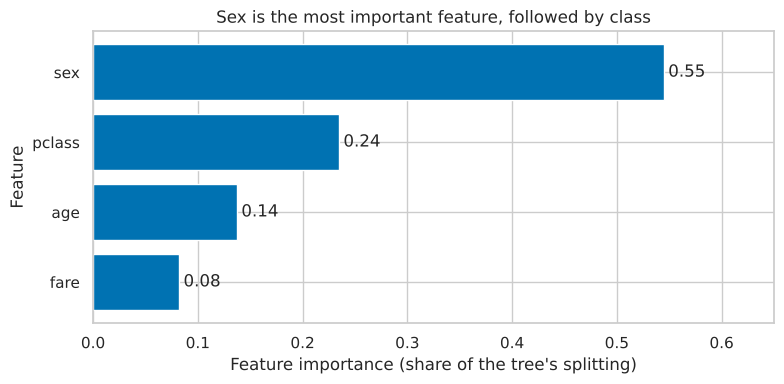

In [12]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
print(importances.sort_values(ascending=False).round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importances.index, importances.values, color=BLUE)
ax.set(title="Sex is the most important feature, followed by class",
       xlabel="Feature importance (share of the tree's splitting)", ylabel="Feature")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.set_xlim(0, 0.65)
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

**Takeaway:** **Sex is by far the most important feature (0.55)**, then ticket class (0.24), age (0.14) and fare (0.08). This matches what I found in the Titanic EDA project: women survived at about 74% vs 19% for men, and survival fell with ticket class.

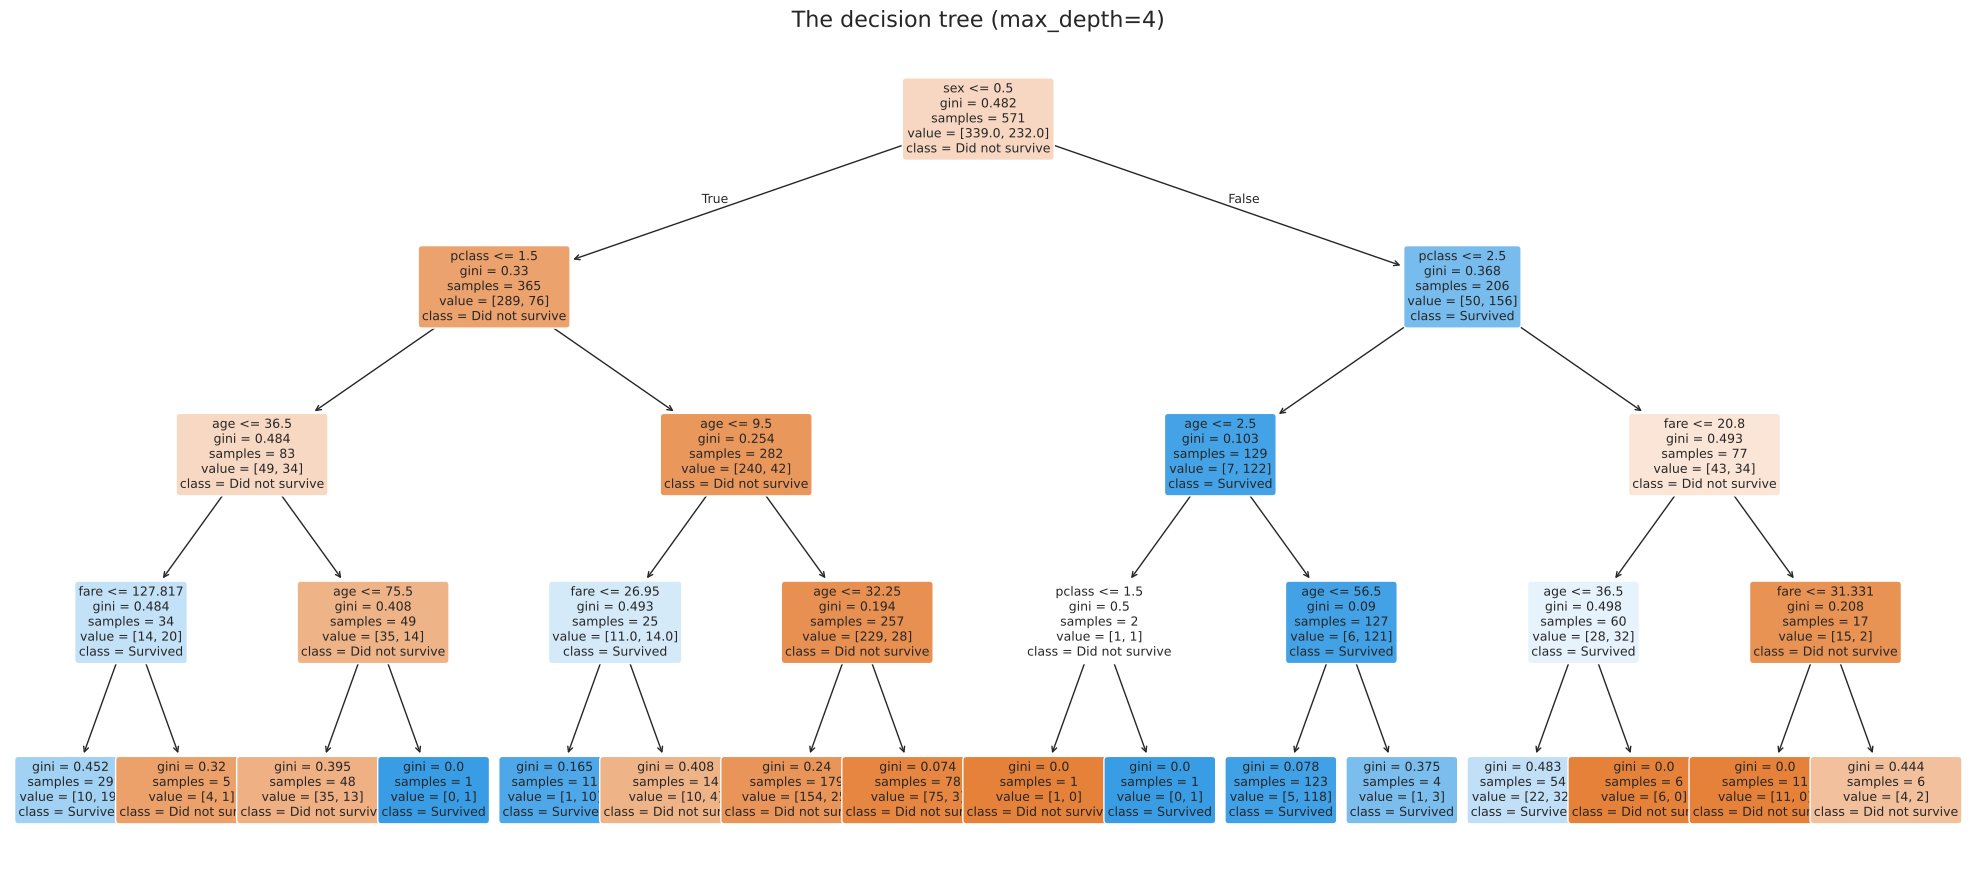

In [13]:
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(model, feature_names=list(X.columns), class_names=["Did not survive", "Survived"],
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("The decision tree (max_depth=4)", fontsize=16)
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=150)
plt.show()

The tree's first question is about **sex**, which confirms that this was the most useful split.

### Try it: predict for two example passengers

In [14]:
examples = pd.DataFrame({
    "pclass": [1, 3],
    "sex":    [1, 0],       # 1 = female, 0 = male
    "age":    [30, 25],
    "fare":   [80.0, 8.0],
}, index=["1st-class woman, age 30", "3rd-class man, age 25"])

probs = model.predict_proba(examples)[:, 1]
result = examples.copy()
result["predicted"] = np.where(model.predict(examples) == 1, "Survived", "Did not survive")
result["chance_of_survival"] = (probs * 100).round(0).astype(int).astype(str) + "%"
result

,pclass,sex,age,fare,predicted,chance_of_survival
"1st-class woman, age 30",1,1,30,80.0,Survived,96%
"3rd-class man, age 25",3,0,25,8.0,Did not survive,14%


## 9. What I Learned

**Results**
- The decision tree reaches **79.7% accuracy on unseen test data**, compared with a **59.4% baseline**, so it adds real value (about +20 percentage points).
- Of 143 test passengers, it got 114 right, with 13 false positives and 16 false negatives. Precision for survivors is 0.76 and recall is 0.72.
- The most important features are **sex (0.55)**, **ticket class (0.24)**, age (0.14) and fare (0.08).
- Training accuracy (84.8%) is higher than test accuracy (79.7%): a small gap, so depth 4 is only mildly overfit. Very deep trees overfit badly (96.8% train vs 77.6% test at depth 12).

**Limitations (honest view)**
1. **Small dataset:** only 714 passengers and a test set of 143, so results are noisy. One passenger changes accuracy by 0.7 points, and cross-validation shows depths 3 to 6 perform about the same.
2. **Dropped rows:** the 177 passengers with missing age are not a random group: about 77% of them were in 3rd class (vs 55% of all passengers) and only about 29% survived (vs 41% of passengers with a known age). Dropping them may bias the model.
3. **Few features:** the model ignores family size, title, port and cabin, which could improve it.
4. **Misses survivors:** recall for survivors is only 72%, so about 28% of people who survived were predicted not to.
5. **Patterns, not causes:** the model finds links in 1912 data. It does not prove why people survived, and it should not be used to make real-world decisions about people.